# FMA Music Genre Classification Analysis

This notebook performs genre classification analysis on the Free Music Archive (FMA) dataset.

## Overview:
Music Genre classification is a key component of Music Information Retrieval (MIR). This analysis covers:
1. Audio Feature Extraction
2. Genre-based Feature Analysis
3. Audio Visualization (Waveforms, Spectrograms, MFCCs)
4. Feature Distribution Analysis
5. Preparation for Classification Models

## 1. Setup and Import Libraries

In [33]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import warnings
from pathlib import Path
from IPython.display import Audio
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print('Libraries imported successfully!')

Libraries imported successfully!


## 2. Load Dataset

In [34]:
# Define paths
PROJECT_ROOT = Path(r'C:\HKBU_FYP')
PROCESSED_ROOT = PROJECT_ROOT / 'processed'
DATA_PATH = PROCESSED_ROOT / 'fma_small_analysis.csv'

# Load dataset
df = pd.read_csv(DATA_PATH)

print(f'Dataset loaded: {len(df)} tracks')
print(f'Columns: {list(df.columns)}')
print(f'\nFirst few rows:')
display(df.head())

Dataset loaded: 8000 tracks
Columns: ['track_id', 'title', 'artist', 'genre', 'duration', 'listens', 'interest', 'audio_path']

First few rows:


,track_id,title,artist,genre,duration,listens,interest,audio_path
0,2,Food,AWOL,Hip-Hop,168,1293,4656,C:\HKBU_FYP\dataset\fma_small\000\000002.mp3
1,5,This World,AWOL,Hip-Hop,206,1151,1933,C:\HKBU_FYP\dataset\fma_small\000\000005.mp3
2,10,Freeway,Kurt Vile,Pop,161,50135,54881,C:\HKBU_FYP\dataset\fma_small\000\000010.mp3
3,140,Queen Of The Wires,Alec K. Redfearn & the Eyesores,Folk,253,1299,1593,C:\HKBU_FYP\dataset\fma_small\000\000140.mp3
4,141,Ohio,Alec K. Redfearn & the Eyesores,Folk,182,725,839,C:\HKBU_FYP\dataset\fma_small\000\000141.mp3


In [35]:
# Genre distribution
genre_counts = df['genre'].value_counts()
print('Genre Distribution:\n')
print(genre_counts)

# Remove Unknown genre for classification
df_clean = df[df['genre'] != 'Unknown'].copy()
print(f'\nDataset after removing Unknown: {len(df_clean)} tracks')
print(f'Number of genres: {df_clean["genre"].nunique()}')

Genre Distribution:

genre
Hip-Hop          1000
Pop              1000
Folk             1000
Experimental     1000
Rock             1000
International    1000
Electronic       1000
Instrumental     1000
Name: count, dtype: int64

Dataset after removing Unknown: 8000 tracks
Number of genres: 8


## 3. Audio Feature Extraction

We'll extract various audio features commonly used in music genre classification:
- **Spectral Features**: Spectral centroid, bandwidth, rolloff
- **Chroma Features**: Pitch class profiles
- **Zero Crossing Rate**: Rate of sign changes in signal
- **MFCCs**: Mel-Frequency Cepstral Coefficients (20 coefficients)
- **Tempo**: Beats per minute
- **RMS Energy**: Root mean square energy

In [36]:
def extract_features(audio_path, sr=22050, duration=30):
    """
    Extract comprehensive audio features from a music file
    
    Parameters:
    - audio_path: Path to audio file
    - sr: Sample rate (default 22050 Hz)
    - duration: Maximum duration to load (seconds)
    
    Returns:
    - Dictionary of extracted features
    """
    try:
        # Load audio
        y, sr = librosa.load(audio_path, sr=sr, duration=duration, mono=True)
        
        # Initialize feature dictionary
        features = {}
        
        # 1. Spectral Centroid (brightness of sound)
        spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        features['spectral_centroid_mean'] = np.mean(spectral_centroids)
        features['spectral_centroid_std'] = np.std(spectral_centroids)
        
        # 2. Spectral Rolloff (frequency below which certain percentage of energy is contained)
        spectral_rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
        features['spectral_rolloff_mean'] = np.mean(spectral_rolloff)
        features['spectral_rolloff_std'] = np.std(spectral_rolloff)
        
        # 3. Spectral Bandwidth
        spectral_bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
        features['spectral_bandwidth_mean'] = np.mean(spectral_bandwidth)
        features['spectral_bandwidth_std'] = np.std(spectral_bandwidth)
        
        # 4. Zero Crossing Rate
        zcr = librosa.feature.zero_crossing_rate(y)[0]
        features['zcr_mean'] = np.mean(zcr)
        features['zcr_std'] = np.std(zcr)
        
        # 5. Chroma Features (12 pitch classes)
        chroma_stft = librosa.feature.chroma_stft(y=y, sr=sr)
        features['chroma_mean'] = np.mean(chroma_stft)
        features['chroma_std'] = np.std(chroma_stft)
        
        # 6. RMS Energy
        rms = librosa.feature.rms(y=y)[0]
        features['rms_mean'] = np.mean(rms)
        features['rms_std'] = np.std(rms)
        
        # 7. MFCCs (Mel-Frequency Cepstral Coefficients) - 20 coefficients
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        for i in range(20):
            features[f'mfcc{i+1}_mean'] = np.mean(mfccs[i])
            features[f'mfcc{i+1}_std'] = np.std(mfccs[i])
        
        # 8. Tempo (BPM)
        try:
            tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
            # Handle both scalar and array tempo values from different librosa versions
            features['tempo'] = float(np.asarray(tempo).flatten()[0])
        except Exception as tempo_error:
            # If tempo detection fails, set a default value
            features['tempo'] = 120.0
            print(f'Warning: Could not detect tempo for {audio_path}, using default 120 BPM')
        
        return features
        
    except Exception as e:
        print(f'Error processing {audio_path}: {str(e)}')
        return None

print('Feature extraction function defined!')

Feature extraction function defined!


In [37]:
# Extract features from a sample of tracks (for demonstration)
# NOTE: Full extraction takes time. Adjust SAMPLE_SIZE as needed.
SAMPLE_SIZE = 100  # Start with 100 tracks, increase for full dataset

# Select balanced sample across genres
per_genre_size = SAMPLE_SIZE // df_clean['genre'].nunique()
sample_list = []
for genre in df_clean['genre'].unique():
    genre_data = df_clean[df_clean['genre'] == genre]
    sample_size = min(len(genre_data), per_genre_size)
    sample_list.append(genre_data.sample(n=sample_size, random_state=42))

sample_df = pd.concat(sample_list, ignore_index=True)

print(f'Extracting features from {len(sample_df)} tracks...')
print('This may take a few minutes...\n')

# Extract features
features_list = []
for idx in range(len(sample_df)):
    if idx % 10 == 0:
        print(f'Processing track {idx+1}/{len(sample_df)}...')
    
    row = sample_df.iloc[idx]
    features = extract_features(row['audio_path'])
    if features:
        features['track_id'] = int(row['track_id'])
        features['genre'] = str(row['genre'])
        features['title'] = str(row['title'])
        features['artist'] = str(row['artist'])
        features_list.append(features)

# Create features dataframe
features_df = pd.DataFrame(features_list)

print(f'\nFeature extraction complete!')
print(f'Features extracted: {len(features_df)} tracks')
print(f'Number of features: {len(features_df.columns) - 4}')

# Save features
output_path = PROCESSED_ROOT / 'genre_classification_features.csv'
features_df.to_csv(output_path, index=False)
print(f'\nFeatures saved to: {output_path}')

Extracting features from 96 tracks...
This may take a few minutes...

Processing track 1/96...
Processing track 11/96...
Processing track 21/96...
Processing track 31/96...
Processing track 41/96...
Processing track 51/96...
Processing track 61/96...
Processing track 71/96...
Processing track 81/96...
Processing track 91/96...

Feature extraction complete!
Features extracted: 96 tracks
Number of features: 53

Features saved to: C:\HKBU_FYP\processed\genre_classification_features.csv


In [38]:
# Display sample features
print('Sample of extracted features:')
display(features_df.head())

print('\nFeature statistics:')
display(features_df.describe())

Sample of extracted features:


,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,spectral_bandwidth_mean,spectral_bandwidth_std,zcr_mean,zcr_std,chroma_mean,chroma_std,...,mfcc18_std,mfcc19_mean,mfcc19_std,mfcc20_mean,mfcc20_std,tempo,track_id,genre,title,artist
0,2306.787327,900.155145,4973.319269,1910.853973,2440.218448,547.265466,0.094813,0.064324,0.499354,0.295956,...,6.466883,-3.455165,6.351714,1.394112,5.994504,129.199219,89848,Hip-Hop,Not the 1s (prod. by Mexicans with Guns),Not The 1s
1,1891.511697,742.959599,4303.915641,1817.260696,2277.756664,484.778324,0.068317,0.037533,0.367160,0.289411,...,7.106272,-2.518176,7.821215,2.786639,8.180317,99.384014,114268,Hip-Hop,poison ivy yard work,Uncle Milk
2,1666.913707,671.269901,3431.154252,1548.687987,1936.506849,448.163185,0.066884,0.038441,0.359882,0.304441,...,9.960264,-8.642042,9.024205,-1.620751,8.737236,143.554688,114275,Hip-Hop,eat it with a fork,Uncle Milk
3,1239.691602,469.651885,2698.664110,1265.371138,1843.636459,361.166485,0.033932,0.018851,0.490753,0.291859,...,3.842575,-0.482394,4.500822,0.199638,4.171955,143.554688,108841,Hip-Hop,Head Cold,Tha Silent Partner
4,1187.406665,654.831389,2775.049886,2129.929129,1902.347378,590.399347,0.023178,0.017172,0.461165,0.325075,...,8.822106,-2.683877,6.315767,-1.923011,5.577920,92.285156,72785,Hip-Hop,Give Her The Length/Give It 2 Her 2times (XXX ...,Tha Silent Partner



Feature statistics:


,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,spectral_bandwidth_mean,spectral_bandwidth_std,zcr_mean,zcr_std,chroma_mean,chroma_std,...,mfcc17_mean,mfcc17_std,mfcc18_mean,mfcc18_std,mfcc19_mean,mfcc19_std,mfcc20_mean,mfcc20_std,tempo,track_id
count,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,...,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000
mean,1882.542214,650.197357,3890.669890,1398.502678,2084.730350,424.987385,0.082871,0.044989,0.371623,0.292219,...,-4.671644,7.127326,-0.264392,7.265542,-3.760088,7.625355,-0.266914,7.663719,116.728285,93457.645833
std,734.098915,310.161478,1602.219329,619.294410,567.366922,164.826057,0.043098,0.029702,0.100507,0.018076,...,5.353111,1.891980,4.555095,2.017861,4.505120,2.533274,5.159513,2.444551,28.467176,37112.681414
min,455.207705,54.895361,643.429443,102.965699,394.402976,70.145931,0.019867,0.002758,0.169722,0.232642,...,-24.339500,3.854107,-14.517043,3.842575,-16.733458,3.599736,-13.804383,3.746756,0.000000,5159.000000
25%,1414.088974,411.618903,2796.239342,880.630621,1858.430997,331.211978,0.053382,0.026659,0.294833,0.284365,...,-6.874941,5.660885,-2.951567,5.657811,-5.913986,5.767434,-2.806677,5.868066,99.384014,74234.750000
50%,1831.001957,623.403641,3769.211239,1446.703030,2133.161823,419.917646,0.075726,0.037143,0.353569,0.293808,...,-4.005186,7.046696,0.641020,7.066340,-3.472430,7.085060,0.247159,7.340355,117.453835,108311.500000
75%,2313.716133,901.693986,4797.523850,1868.999557,2496.308692,546.392723,0.099597,0.056984,0.451676,0.300812,...,-1.169097,8.095328,2.121368,8.339149,-0.883181,9.098182,2.727477,8.830658,135.999178,121657.000000
max,4675.559037,1388.272706,8691.432933,2689.659206,3334.625149,944.297447,0.258755,0.165306,0.622166,0.335974,...,5.342388,13.039091,15.852467,12.400736,7.470350,17.400068,9.804762,17.266645,184.570312,137898.000000


## 4. Audio Visualization

Visualize audio characteristics for different genres to understand their distinctive features.

In [39]:
def visualize_audio(audio_path, title="Audio Analysis", duration=30):
    """
    Create comprehensive visualization of audio file:
    - Waveform
    - Spectrogram
    - Chroma Features
    - MFCC
    """
    # Load audio
    y, sr = librosa.load(audio_path, sr=22050, duration=duration, mono=True)
    
    # Create figure with subplots
    fig, axes = plt.subplots(4, 1, figsize=(14, 12))
    
    # 1. Waveform
    librosa.display.waveshow(y, sr=sr, ax=axes[0], color='steelblue')
    axes[0].set_title(f'Waveform: {title}')
    axes[0].set_xlabel('Time (s)')
    axes[0].set_ylabel('Amplitude')
    axes[0].grid(True, alpha=0.3)
    
    # 2. Spectrogram
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    img = librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz', ax=axes[1], cmap='viridis')
    axes[1].set_title('Spectrogram')
    fig.colorbar(img, ax=axes[1], format='%+2.0f dB')
    
    # 3. Chroma Features
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    img = librosa.display.specshow(chroma, sr=sr, x_axis='time', y_axis='chroma', ax=axes[2], cmap='coolwarm')
    axes[2].set_title('Chromagram')
    fig.colorbar(img, ax=axes[2])
    
    # 4. MFCC
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    img = librosa.display.specshow(mfccs, sr=sr, x_axis='time', ax=axes[3], cmap='plasma')
    axes[3].set_title('MFCC (Mel-Frequency Cepstral Coefficients)')
    fig.colorbar(img, ax=axes[3])
    
    plt.tight_layout()
    plt.show()

print('Audio visualization function defined!')

Audio visualization function defined!



Visualizing: Not The 1s - Not the 1s (prod. by Mexicans with Guns) (Hip-Hop)

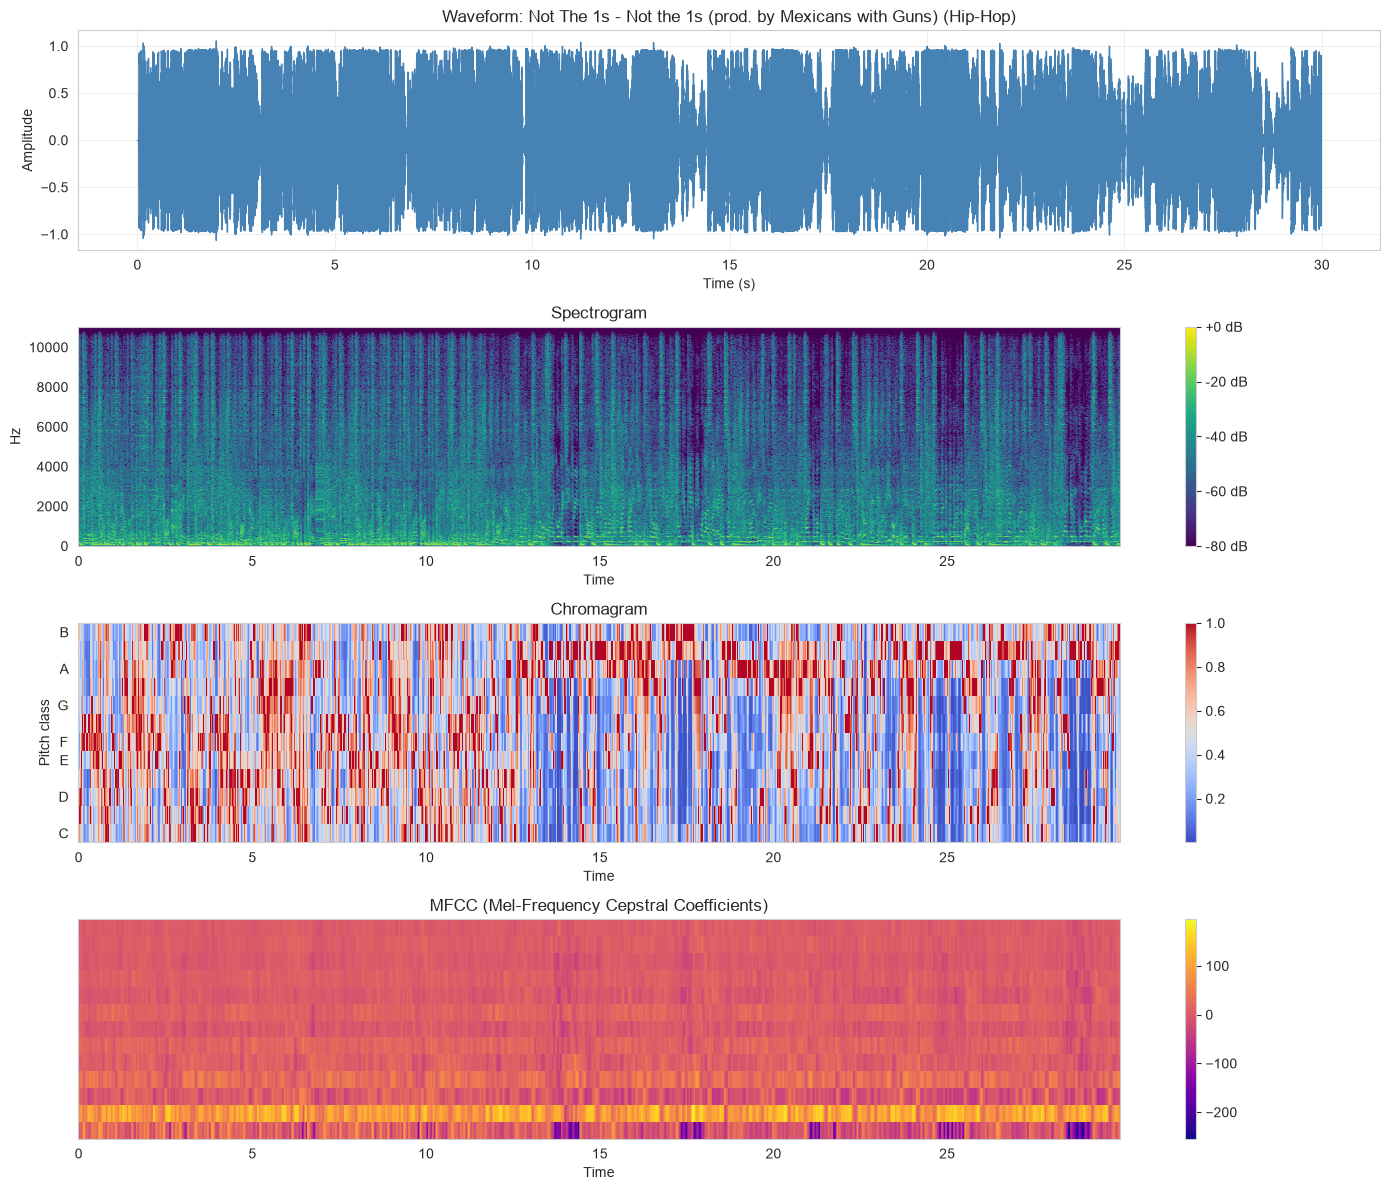


Visualizing: Garmisch - And Now We Stand Against The Wall (Pop)


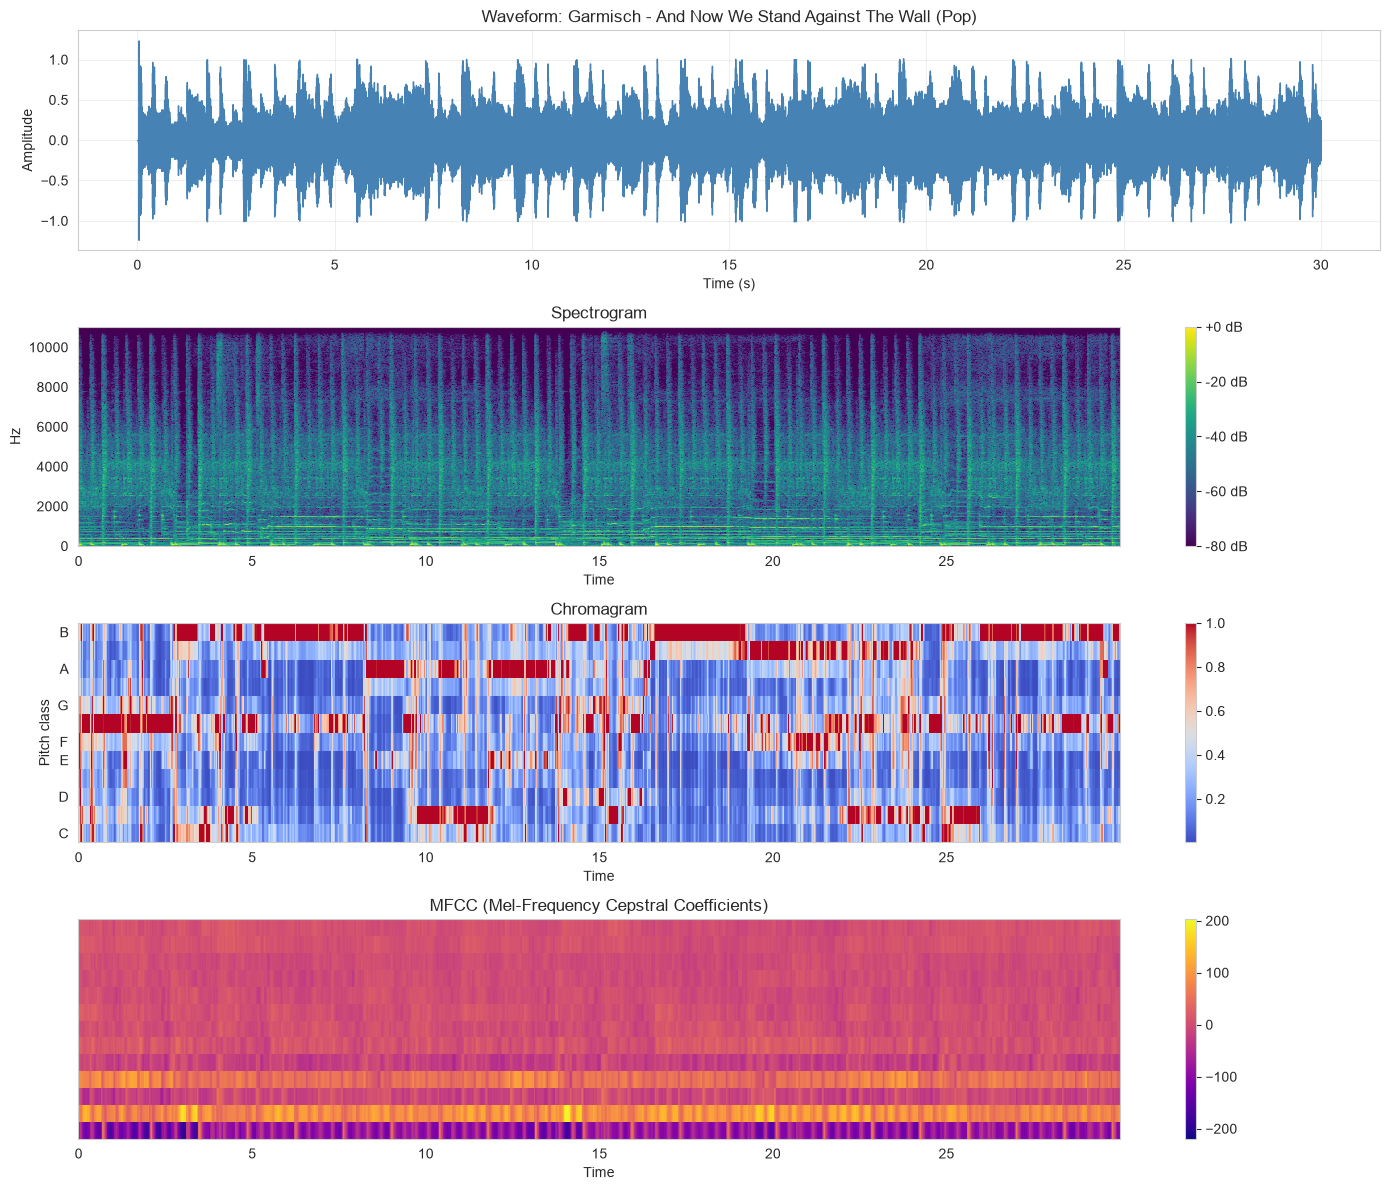


Visualizing: Josh Woodward - Cien Volando (Folk)


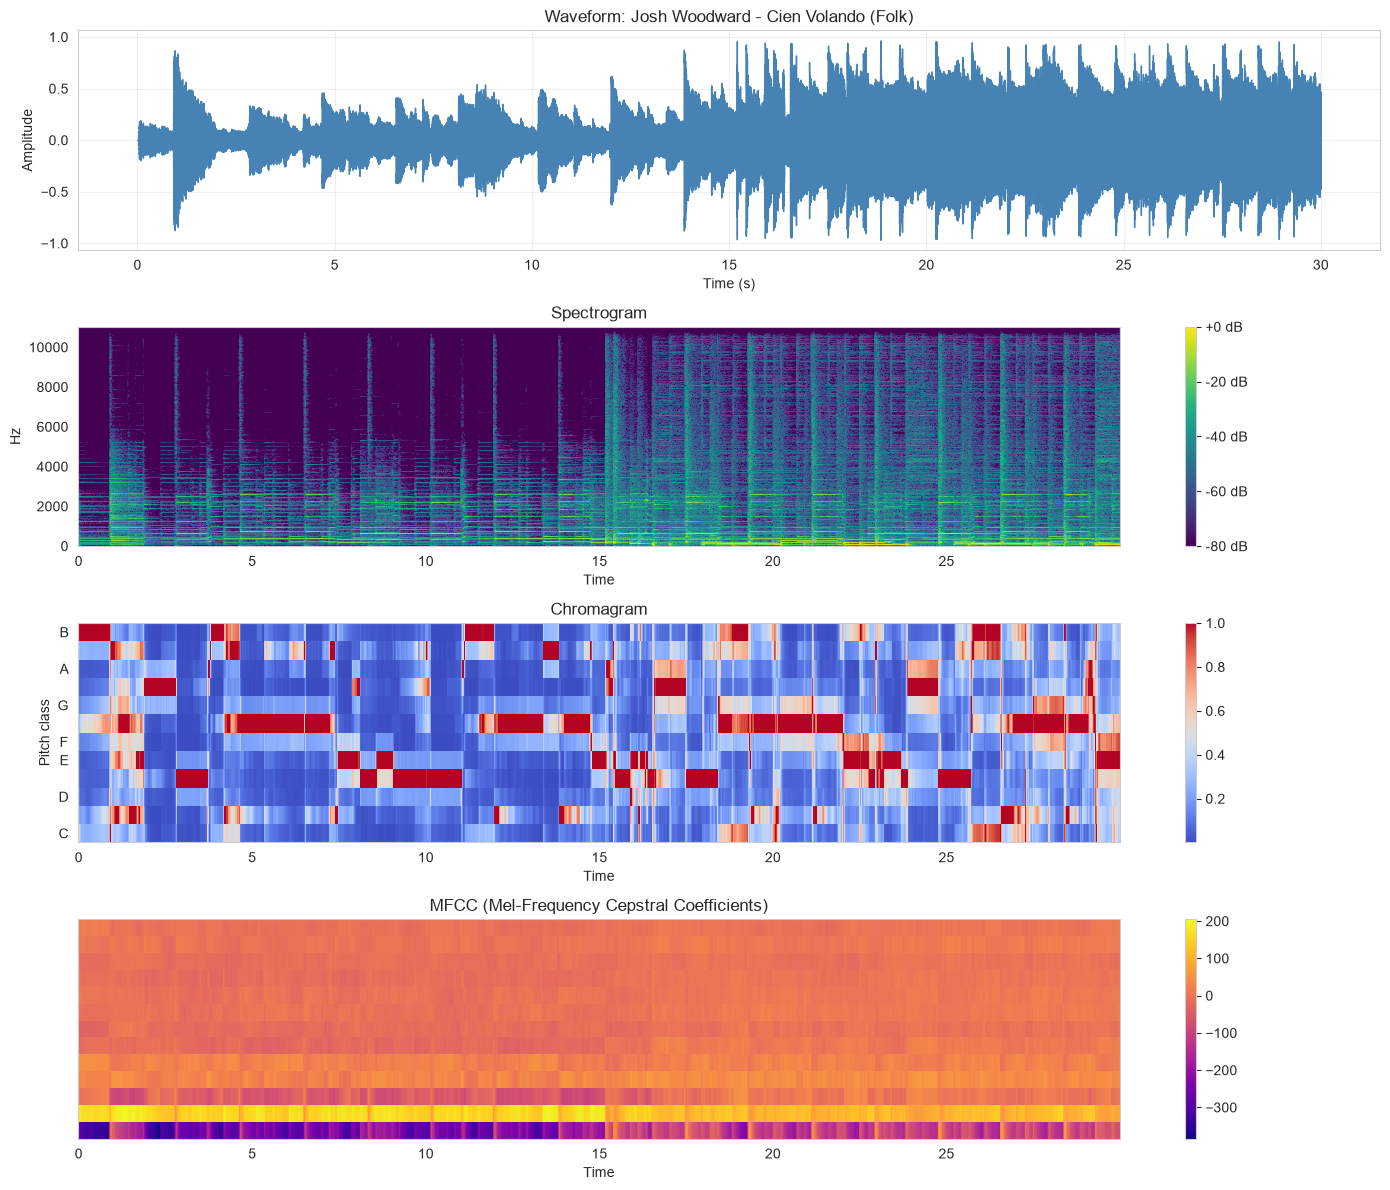

In [40]:
# Visualize sample tracks from different genres
genres_to_visualize = features_df['genre'].unique()[:3]  # First 3 genres

for genre in genres_to_visualize:
    # Get a sample track from this genre
    sample = features_df[features_df['genre'] == genre].iloc[0]
    # Get audio path from original dataframe
    track_info = df_clean[df_clean['track_id'] == sample['track_id']]
    if len(track_info) == 0:
        print(f'Audio file not found for track {sample["track_id"]}')
        continue
    audio_path = track_info['audio_path'].values[0]
    
    title = f"{sample['artist']} - {sample['title']} ({genre})"
    print(f'\nVisualizing: {title}')
    
    # Create visualization
    visualize_audio(audio_path, title=title, duration=30)
    
    # Display audio player
    display(Audio(audio_path))

## 5. Feature Analysis by Genre

Analyze how different features vary across genres.

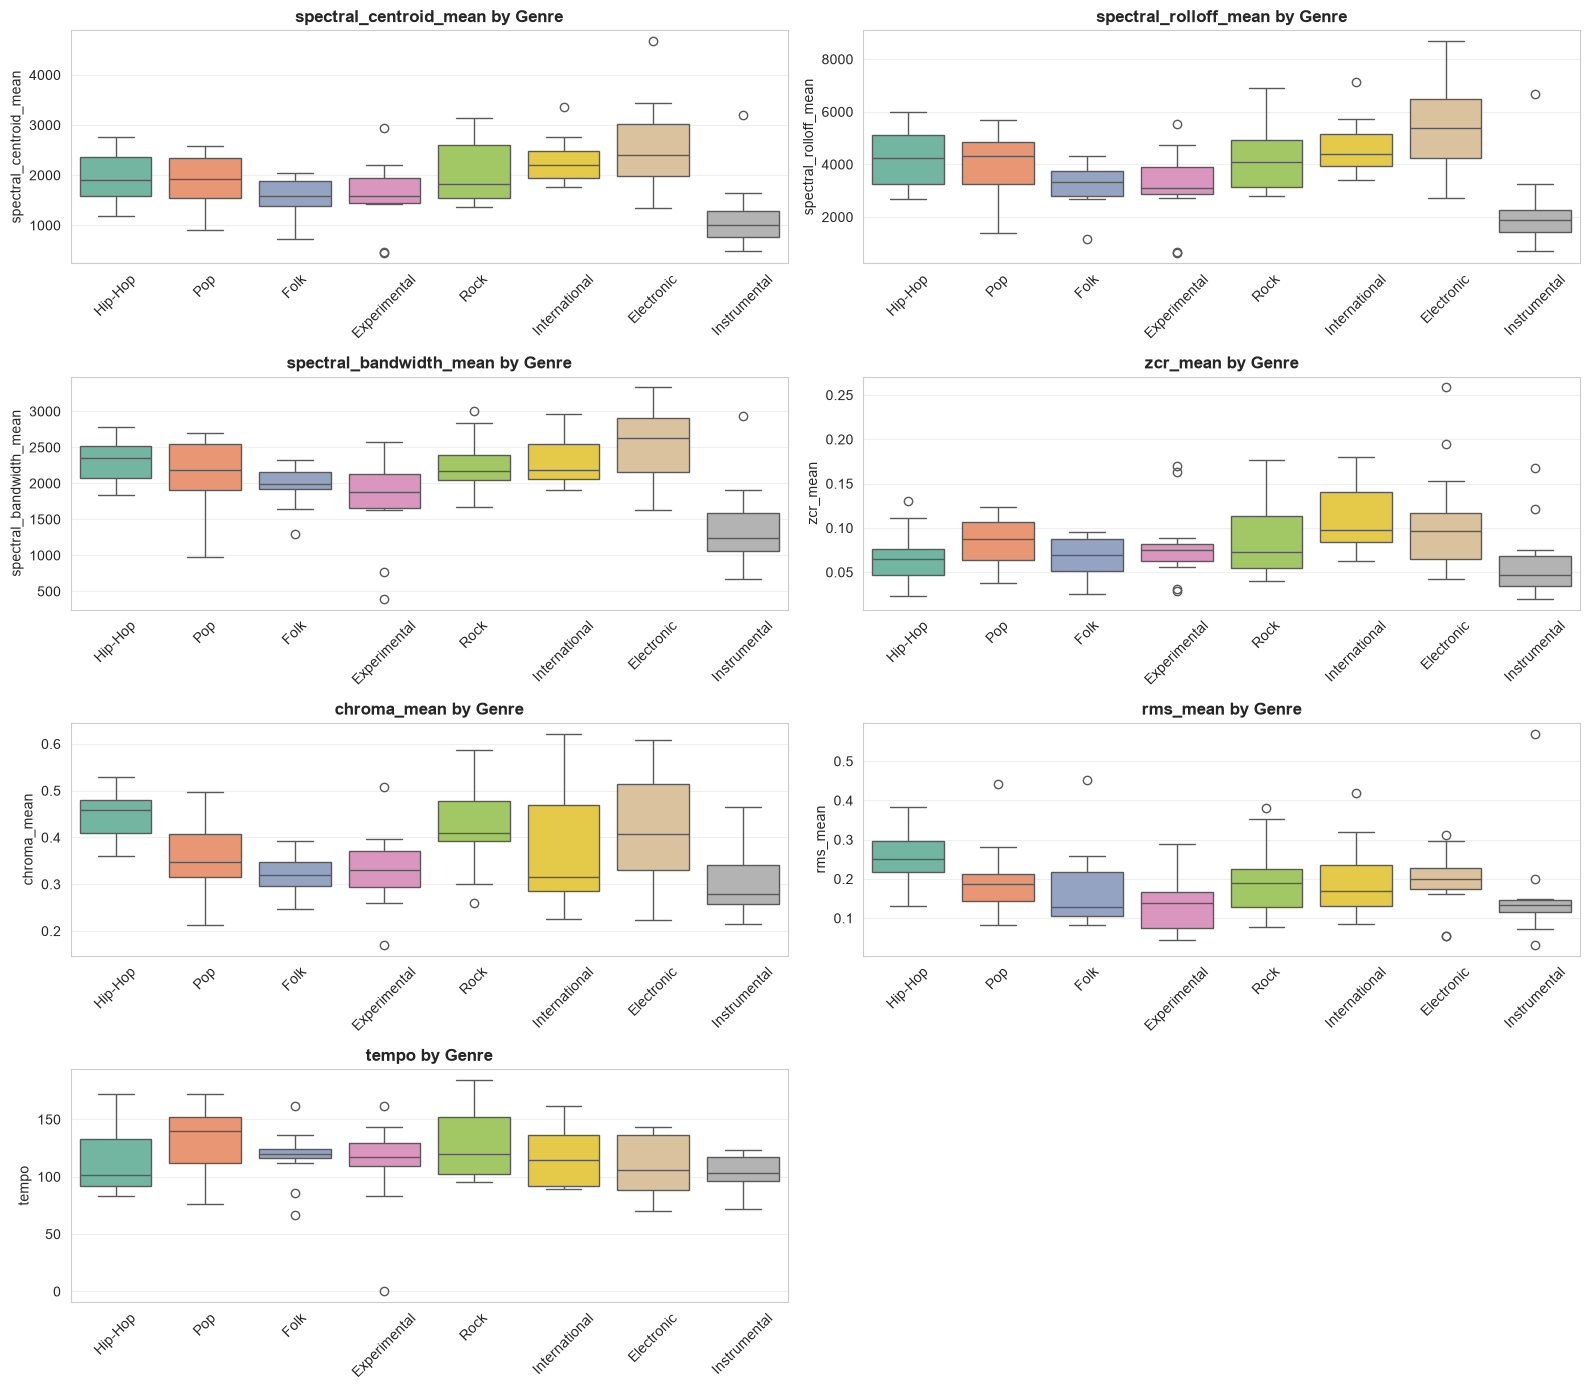

Key observations:
- Spectral features show how "bright" or "dark" genres sound
- Zero Crossing Rate indicates percussive vs. harmonic content
- Tempo variations show rhythmic differences between genres


In [41]:
# Select key features for analysis
key_features = [
    'spectral_centroid_mean',
    'spectral_rolloff_mean',
    'spectral_bandwidth_mean',
    'zcr_mean',
    'chroma_mean',
    'rms_mean',
    'tempo'
]

# Create boxplots for key features across genres
fig, axes = plt.subplots(4, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=features_df, x='genre', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'{feature} by Genre', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].grid(axis='y', alpha=0.3)

# Remove empty subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

print('Key observations:')
print('- Spectral features show how "bright" or "dark" genres sound')
print('- Zero Crossing Rate indicates percussive vs. harmonic content')
print('- Tempo variations show rhythmic differences between genres')

In [42]:
# Genre statistics for key features
print('Feature Statistics by Genre:\n')
for feature in key_features:
    print(f'\n{feature.upper()}:')
    genre_stats = features_df.groupby('genre')[feature].agg(['mean', 'std', 'min', 'max'])
    display(genre_stats.round(2))

Feature Statistics by Genre:


SPECTRAL_CENTROID_MEAN:


,mean,std,min,max
genre,,,,
Electronic,2549.63,969.63,1338.29,4675.56
Experimental,1598.22,680.23,455.21,2944.20
Folk,1587.38,382.02,721.59,2048.06
Hip-Hop,1942.10,549.51,1187.41,2760.33
Instrumental,1184.12,715.64,482.19,3199.82
International,2289.09,462.51,1769.32,3351.34
Pop,1902.84,556.91,916.29,2587.26
Rock,2006.95,603.98,1358.59,3149.34



SPECTRAL_ROLLOFF_MEAN:


,mean,std,min,max
genre,,,,
Electronic,5399.70,1850.61,2719.56,8691.43
Experimental,3131.48,1427.69,643.43,5547.19
Folk,3244.66,858.63,1152.33,4306.04
Hip-Hop,4218.77,1174.46,2698.66,5989.64
Instrumental,2233.19,1551.36,717.89,6680.71
International,4665.34,1026.15,3409.60,7117.52
Pop,3979.77,1355.57,1374.04,5705.16
Rock,4252.45,1343.43,2796.58,6896.12



SPECTRAL_BANDWIDTH_MEAN:


...

,mean,std,min,max
genre,,,,
Electronic,0.42,0.12,0.22,0.61
Experimental,0.33,0.08,0.17,0.51
Folk,0.32,0.04,0.25,0.39
Hip-Hop,0.45,0.05,0.36,0.53
Instrumental,0.30,0.07,0.21,0.46
International,0.37,0.13,0.23,0.62
Pop,0.36,0.08,0.21,0.50
Rock,0.42,0.09,0.26,0.59



RMS_MEAN:


,mean,std,min,max
genre,,,,
Electronic,0.19,0.08,0.05,0.31
Experimental,0.14,0.08,0.04,0.29
Folk,0.17,0.11,0.08,0.45
Hip-Hop,0.26,0.07,0.13,0.38
Instrumental,0.16,0.14,0.03,0.57
International,0.20,0.10,0.08,0.42
Pop,0.20,0.09,0.08,0.44
Rock,0.20,0.09,0.08,0.38



TEMPO:


,mean,std,min,max
genre,,,,
Electronic,110.52,25.96,69.84,143.55
Experimental,110.74,40.14,0.00,161.50
Folk,117.74,23.63,66.26,161.50
Hip-Hop,113.03,27.84,83.35,172.27
Instrumental,102.84,17.48,71.78,123.05
International,116.27,24.08,89.10,161.50
Pop,134.47,27.44,76.00,172.27
Rock,128.21,30.76,95.70,184.57


## 6. MFCC Analysis

MFCCs are among the most important features for music genre classification.

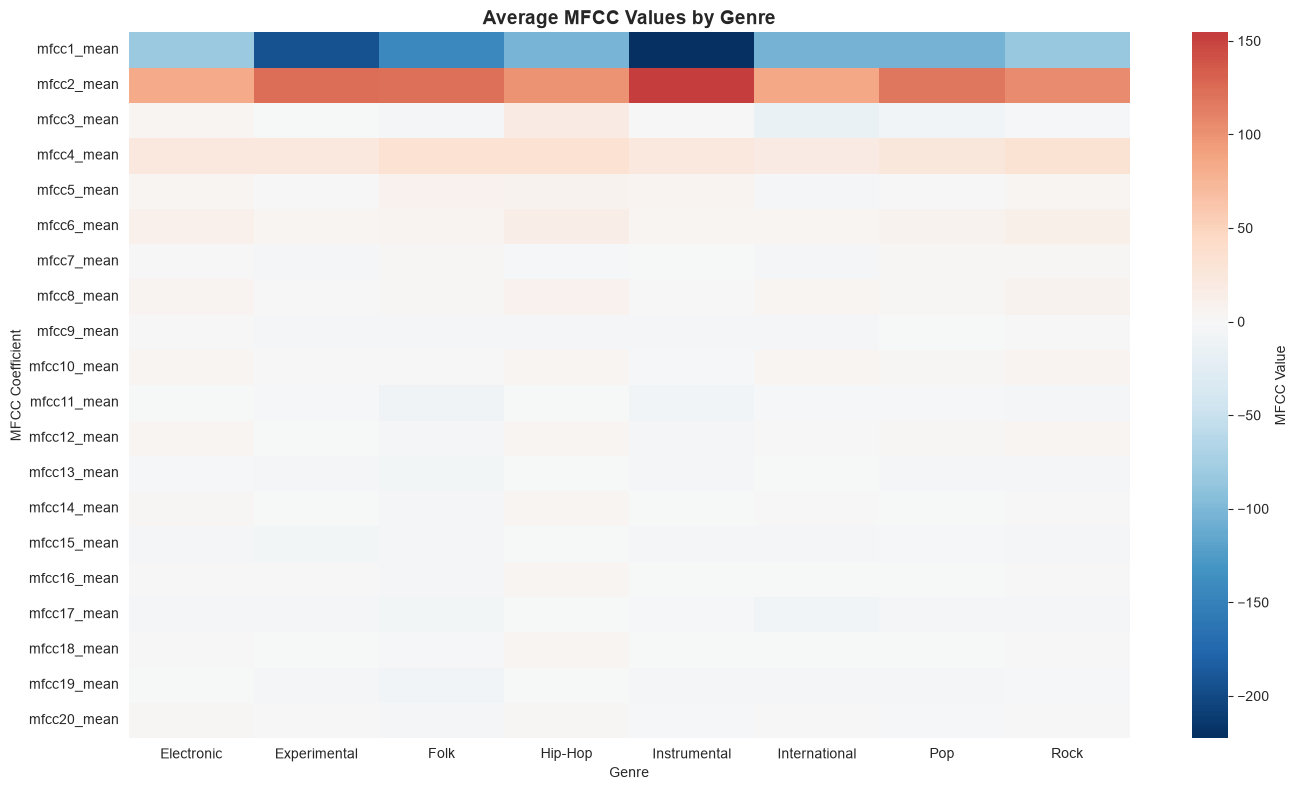

MFCC patterns show unique spectral characteristics for each genre


In [43]:
# Visualize MFCC means across genres
mfcc_columns = [col for col in features_df.columns if col.startswith('mfcc') and col.endswith('_mean')]

# Calculate mean MFCCs per genre
mfcc_by_genre = features_df.groupby('genre')[mfcc_columns].mean()

# Plot heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(mfcc_by_genre.T, cmap='RdBu_r', center=0, annot=False, 
            cbar_kws={'label': 'MFCC Value'})
plt.title('Average MFCC Values by Genre', fontsize=14, fontweight='bold')
plt.xlabel('Genre')
plt.ylabel('MFCC Coefficient')
plt.tight_layout()
plt.show()

print('MFCC patterns show unique spectral characteristics for each genre')

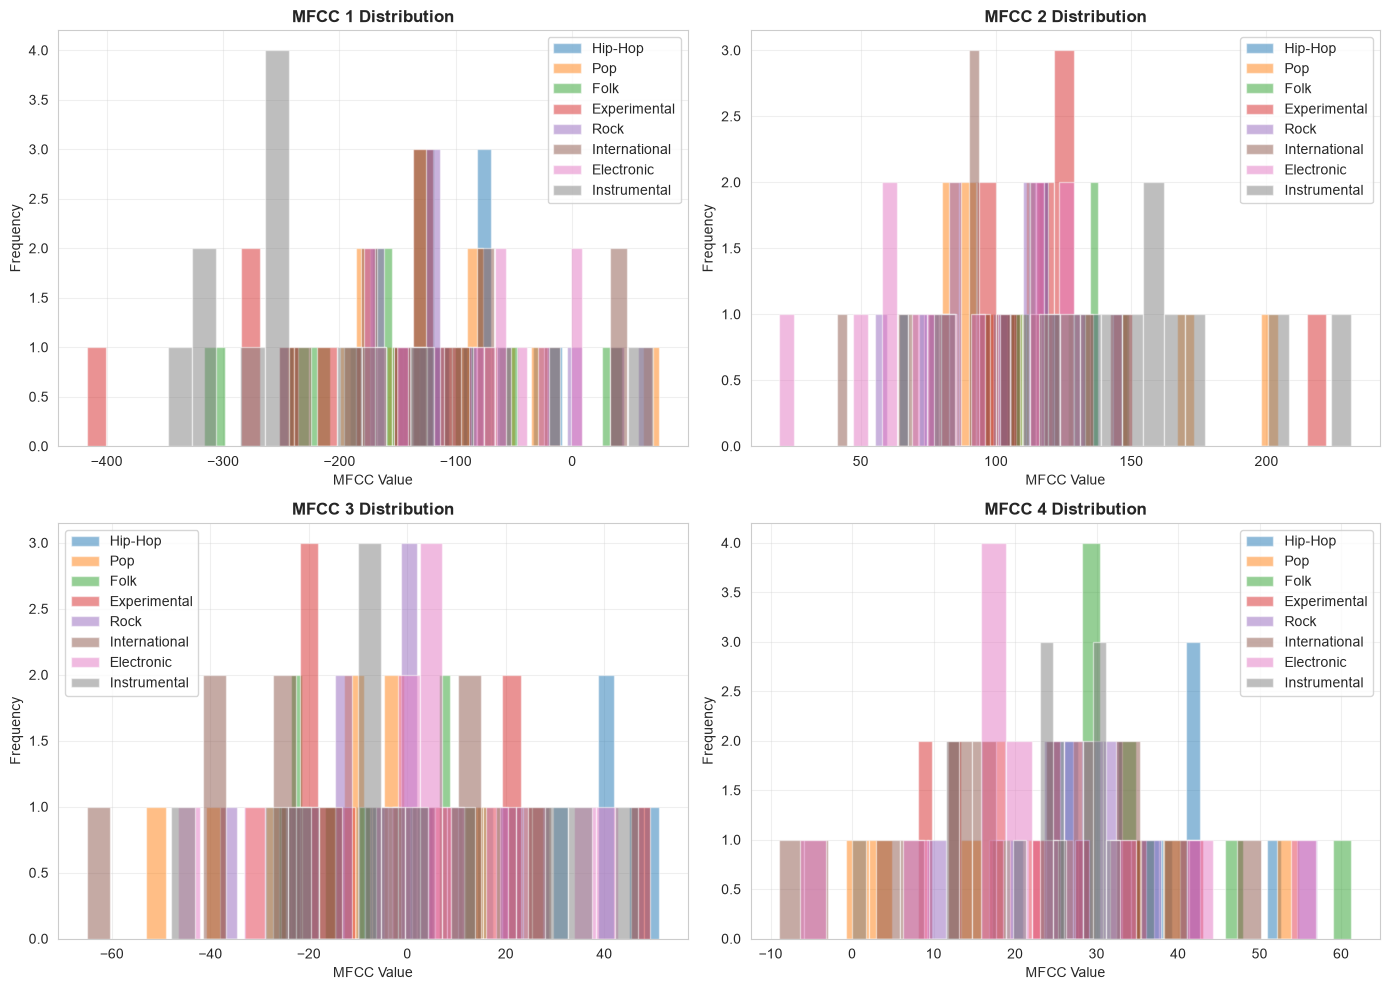

In [44]:
# Visualize first 4 MFCCs distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx in range(4):
    mfcc_col = f'mfcc{idx+1}_mean'
    for genre in features_df['genre'].unique():
        genre_data = features_df[features_df['genre'] == genre][mfcc_col]
        axes[idx].hist(genre_data, alpha=0.5, label=genre, bins=20)
    
    axes[idx].set_title(f'MFCC {idx+1} Distribution', fontweight='bold')
    axes[idx].set_xlabel('MFCC Value')
    axes[idx].set_ylabel('Frequency')
    axes[idx].legend()
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Feature Correlation Analysis

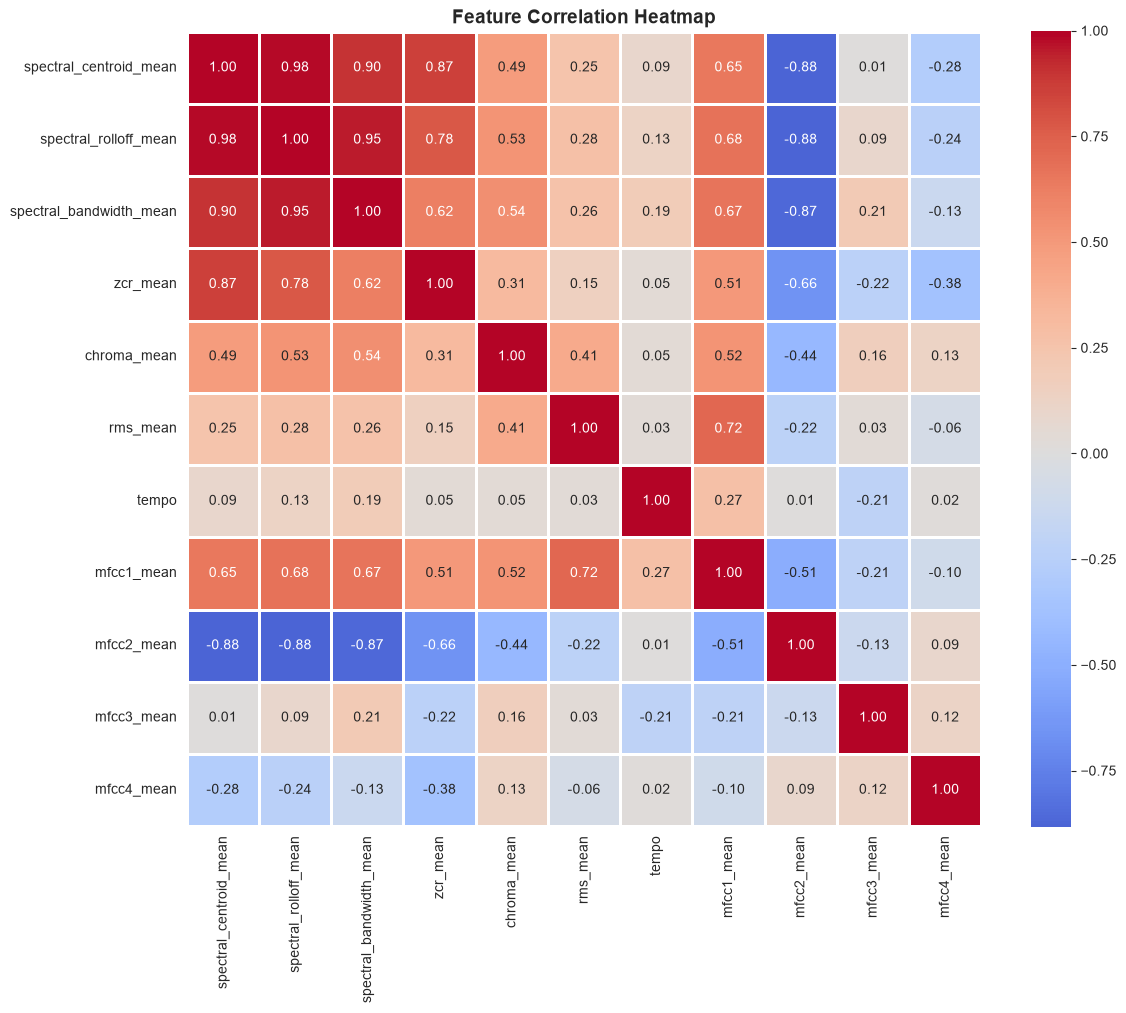

High correlations indicate redundant features
Low correlations suggest independent information


In [45]:
# Select numeric features for correlation analysis
numeric_features = features_df.select_dtypes(include=[np.number]).columns.tolist()

# Calculate correlation matrix
correlation_matrix = features_df[numeric_features].corr()

# Plot correlation heatmap (for key features)
key_numeric = key_features + ['mfcc1_mean', 'mfcc2_mean', 'mfcc3_mean', 'mfcc4_mean']
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix.loc[key_numeric, key_numeric], 
            annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('High correlations indicate redundant features')
print('Low correlations suggest independent information')

## 8. Prepare Data for Classification

Prepare features and labels for machine learning models.

In [46]:
# Separate features and labels
X = features_df[numeric_features].values
y = features_df['genre'].values

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Print label mapping
print('Genre Label Encoding:')
for idx, genre in enumerate(label_encoder.classes_):
    print(f'{idx}: {genre}')

print(f'\nFeature matrix shape: {X.shape}')
print(f'Label vector shape: {y_encoded.shape}')

Genre Label Encoding:
0: Electronic
1: Experimental
2: Folk
3: Hip-Hop
4: Instrumental
5: International
6: Pop
7: Rock

Feature matrix shape: (96, 54)
Label vector shape: (96,)


In [47]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Features standardized (mean=0, std=1)')
print(f'\nScaled feature statistics:')
print(f'Mean: {X_scaled.mean(axis=0)[:5]}')
print(f'Std: {X_scaled.std(axis=0)[:5]}')

Features standardized (mean=0, std=1)

Scaled feature statistics:
Mean: [-1.38777878e-16  1.48029737e-16  3.14563190e-16 -3.23815049e-16
 -2.26670534e-16]
Std: [1. 1. 1. 1. 1.]


In [48]:
# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print('Data Split:')
print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set: {X_test.shape[0]} samples')

# Check class distribution
print('\nTraining set genre distribution:')
train_genre_counts = pd.Series(y_train).value_counts().sort_index()
for idx, count in train_genre_counts.items():
    print(f'{label_encoder.classes_[idx]}: {count}')

print('\nTest set genre distribution:')
test_genre_counts = pd.Series(y_test).value_counts().sort_index()
for idx, count in test_genre_counts.items():
    print(f'{label_encoder.classes_[idx]}: {count}')

Data Split:
Training set: 76 samples
Test set: 20 samples

Training set genre distribution:
Electronic: 10
Experimental: 10
Folk: 9
Hip-Hop: 9
Instrumental: 9
International: 10
Pop: 9
Rock: 10

Test set genre distribution:
Electronic: 2
Experimental: 2
Folk: 3
Hip-Hop: 3
Instrumental: 3
International: 2
Pop: 3
Rock: 2


In [49]:
# Save processed data for modeling
import pickle

# Save to processed folder
data_dict = {
    'X_train': X_train,
    'X_test': X_test,
    'y_train': y_train,
    'y_test': y_test,
    'label_encoder': label_encoder,
    'scaler': scaler,
    'feature_names': numeric_features
}

output_pickle = PROCESSED_ROOT / 'genre_classification_data.pkl'
with open(output_pickle, 'wb') as f:
    pickle.dump(data_dict, f)

print(f'Processed data saved to: {output_pickle}')
print('\nThis data is ready for use in classification models!')

Processed data saved to: C:\HKBU_FYP\processed\genre_classification_data.pkl

This data is ready for use in classification models!


## 9. Feature Importance Preview

Quick analysis using Random Forest to identify important features.

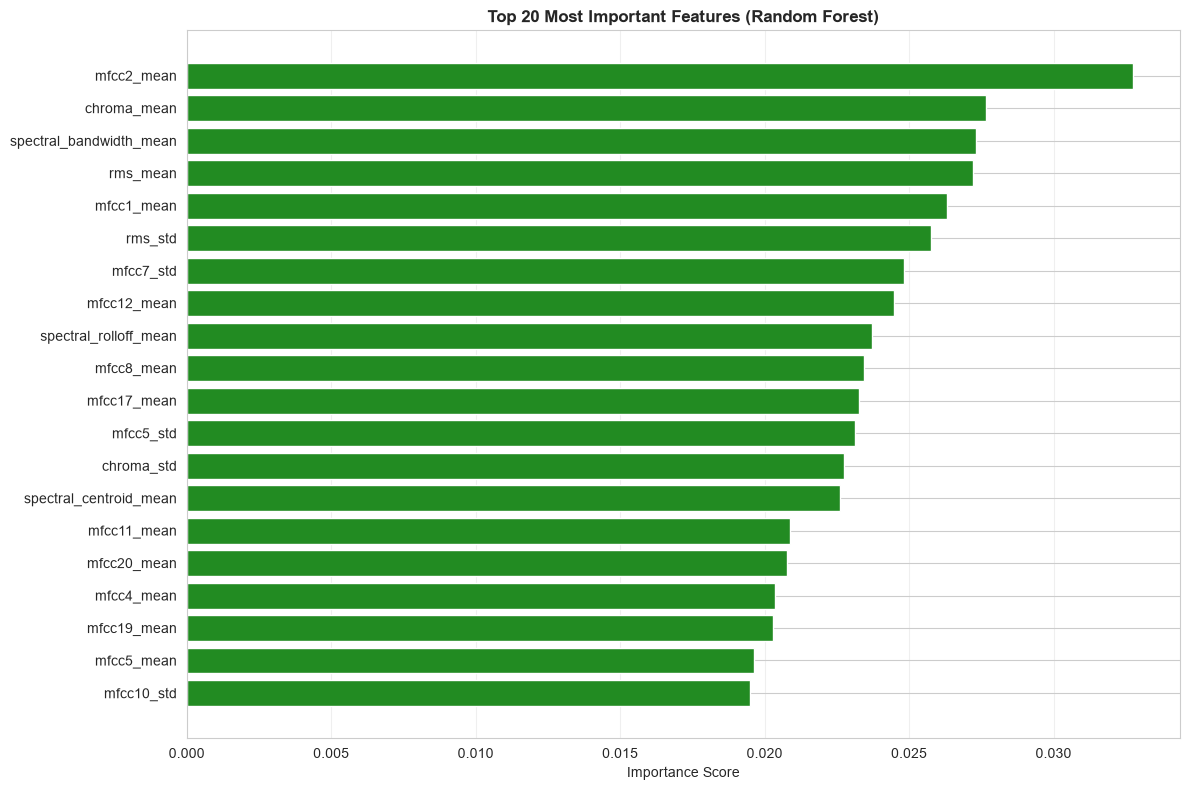


Random Forest Quick Evaluation:
Training Accuracy: 1.0000
Test Accuracy: 0.4500


In [50]:
from sklearn.ensemble import RandomForestClassifier

# Train a quick Random Forest model
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Get feature importances
importances = rf.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': numeric_features,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(12, 8))
top_features = feature_importance_df.head(20)
plt.barh(range(len(top_features)), top_features['Importance'], color='forestgreen')
plt.yticks(range(len(top_features)), top_features['Feature'])
plt.xlabel('Importance Score')
plt.title('Top 20 Most Important Features (Random Forest)', fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# Quick evaluation
train_score = rf.score(X_train, y_train)
test_score = rf.score(X_test, y_test)

print(f'\nRandom Forest Quick Evaluation:')
print(f'Training Accuracy: {train_score:.4f}')
print(f'Test Accuracy: {test_score:.4f}')

## 10. Summary and Next Steps

In [51]:
print('='*70)
print('GENRE CLASSIFICATION ANALYSIS SUMMARY')
print('='*70)

print('\n1. DATASET:')
print(f'   - Total tracks analyzed: {len(features_df)}')
print(f'   - Number of genres: {features_df["genre"].nunique()}')
print(f'   - Genres: {sorted(features_df["genre"].unique())}')

print('\n2. FEATURES EXTRACTED:')
print(f'   - Total features: {len(numeric_features)}')
print(f'   - Feature categories:')
print(f'     • Spectral features: 6')
print(f'     • Chroma features: 2')
print(f'     • Zero Crossing Rate: 2')
print(f'     • RMS Energy: 2')
print(f'     • MFCCs: 40 (20 coefficients × 2 statistics)')
print(f'     • Tempo: 1')

print('\n3. DATA SPLIT:')
print(f'   - Training set: {len(X_train)} samples')
print(f'   - Test set: {len(X_test)} samples')
print(f'   - Split ratio: 80/20')

print('\n4. KEY FINDINGS:')
print('   - Different genres show distinct patterns in spectral features')
print('   - MFCCs capture important timbral characteristics')
print('   - Features are standardized and ready for modeling')

print('\n5. NEXT STEPS:')
print('   □ Build classification models:')
print('     • K-Nearest Neighbors (KNN)')
print('     • Support Vector Machine (SVM)')
print('     • Random Forest')
print('     • Gradient Boosting (XGBoost/LightGBM)')
print('     • Deep Neural Networks')
print('     • Convolutional Neural Networks (CNN) with spectrograms')
print('   □ Perform hyperparameter tuning')
print('   □ Compare model performances')
print('   □ Analyze misclassifications')
print('   □ Deploy best model')

print('\n' + '='*70)
print('ANALYSIS COMPLETE! Ready for model building.')
print('='*70)

GENRE CLASSIFICATION ANALYSIS SUMMARY

1. DATASET:
   - Total tracks analyzed: 96
   - Number of genres: 8
   - Genres: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock']

2. FEATURES EXTRACTED:
   - Total features: 54
   - Feature categories:
     • Spectral features: 6
     • Chroma features: 2
     • Zero Crossing Rate: 2
     • RMS Energy: 2
     • MFCCs: 40 (20 coefficients × 2 statistics)
     • Tempo: 1

3. DATA SPLIT:
   - Training set: 76 samples
   - Test set: 20 samples
   - Split ratio: 80/20

4. KEY FINDINGS:
   - Different genres show distinct patterns in spectral features
   - MFCCs capture important timbral characteristics
   - Features are standardized and ready for modeling

5. NEXT STEPS:
   □ Build classification models:
     • K-Nearest Neighbors (KNN)
     • Support Vector Machine (SVM)
     • Random Forest
     • Gradient Boosting (XGBoost/LightGBM)
     • Deep Neural Networks
     • Convolutional Neural Networks (CN